# Code to evaluate (C)DVTINY or other models using comparative_layers and stored in .keras format
(C)DVTINY stands for **(Comparative) DepthwiseVersatile for TINY-ML**

Copyright Radu DOGARU and IOANA DOGARU , Oct. 2026   contact: radu.dogaru@upb.ro

Last updates -  30 Oct. 2026,



# 0 - INITS and UTILITY

#  0.1 - inits

In [1]:
# CELL 0.1
# Choice of backend and computing platform
#--------------------------------------------
import os
mediu_sw_calcul='tensorflow' # "jax" sau "tensorflow" sau "torch"
# JAX is preferred;
# Use tensorflow only for classic synapses (multiplicative) allowing also .tflite conversion
# and MAC computations.

os.environ["KERAS_BACKEND"] = mediu_sw_calcul

import keras
import numpy as np
my_back=keras.config.backend()
print('Backend: ',my_back)
print('Keras version: ',keras.__version__)
if my_back=='tensorflow':
  import tensorflow as tf
  print('TF versiunea: ',tf.__version__)

import jax
my_device=(jax.devices()[0].platform).upper()
print('Actual computing platform: ',my_device)

Backend:  tensorflow
Keras version:  3.13.2
TF versiunea:  2.20.0
Actual computing platform:  GPU


# 0.2 - Utilities

In [3]:
#
# Copyright Radu Dogaru, 1 June 2024
#
def truncate_float(float_number, decimal_places):
    multiplier = 10 ** decimal_places
    return int(float_number * multiplier) / multiplier

# Evaluates MAC & Accumulate - needs tensorflow backend and classic layers (not user-defined)
if my_back=='tensorflow':
  import tensorflow as tf
  from tensorflow.python.profiler import option_builder
  from tensorflow.python.profiler import model_analyzer

def get_flops(model):
    # [asistent Gemini, Google, apr. 2026]
    full_model = tf.function(lambda x: model(x))
    concrete_func = full_model.get_concrete_function(
        tf.TensorSpec([1] + list(model.input_shape[1:]), model.inputs[0].dtype)
    )

    opts = option_builder.ProfileOptionBuilder.float_operation()

    opts['output'] = 'none'
    # -----------------------------------
    # 3. Rulăm analiza
    graph_info = model_analyzer.profile(concrete_func.graph, options=opts)

    flops = graph_info.total_float_ops
    return flops

#-----------------------------------------------------------------------
# Datagen --> tensor conversion
# Copyright Radu Dogaru, 1 June 2024
# requires Tensorflow backend
#------------------------------------------------------------
def conv_tensor(datagen, num_batches):
    for x_test, y_test in datagen:
            break;
    for b in range(num_batches-1):
        for x, y in datagen:
            break;
        x_test= tf.concat([x_test, x], axis=0)
        y_test= tf.concat([y_test, y], axis=0)
    return x_test, y_test

# Added May 30, 2026 - plays a sound when training is done
from IPython.display import Audio, display

def play_alert():
    framerate = 44100
    duration_seconds = 1.0
    frequency_hz = 440.0
    t = np.linspace(0, duration_seconds, int(framerate * duration_seconds))
    audio_data = np.sin(2 * np.pi * frequency_hz * t)
    display(Audio(audio_data, rate=framerate, autoplay=True))

# ========== for browsing model list =====================================
import requests
def listeaza_fisiere_github(owner, repo, folder=""):
  # Construim adresa API-ului GitHub pentru directorul dorit
  api_url = f"https://api.github.com/repos/{owner}/{repo}/contents/{folder}"

  response = requests.get(api_url)

  if response.status_code == 200:
    items = response.json()
    print(f"📁 Git folder content '{folder}' :\n")
    print(f"{'Type':<10} | {'Name':<30} | {'Size (bytes)'}")
    print("-" * 60)

    for item in items:
      tip = "📁 Folder" if item["type"] == "dir" else "📄 File"
      nume = item["name"]
      dimensiune = item.get("size", 0)
      print(f"{tip:<10} | {nume:<30} | {dimensiune}")
  else:
    print(
        f"Error in accessing GitHub (Cod {response.status_code}): Asigură-te"
        " că repository-ul este public și calea este corectă."
    )

# 1 - DATA SETS
Run either cell 1.1 (tensor) or 1.2. ("data_generator")

# 1.1 - Tensor data

In [ ]:
# run only for extra datasest
!pip install extra-keras-datasets
from extra_keras_datasets import svhn, usps

In [4]:
# CELULA 1.1 - date in format tensor import din Keras
# EMNIST - set de date in Kaggle
#-----------------------------------------------------------------------
from keras.datasets import mnist, cifar10, cifar100, fashion_mnist
from datasets import load_dataset
import numpy as np

datagen=False
out_coding='cat' # modul categorical ; poate si 'non'
in_coding='clast'  # canalele de intrare sunt in ordinea "channel-last " (pot fi si cfirst - de ex in Pytorch )
num_replici=8  # TPU Kaggle (1 in Colab)

test_exists=False
dataset='mnist' # cifar10, cifar20, or cifar100, mnist or emnist or  f-mnist

if my_device=='TPU':
    batch_size=num_replici*16  #
else:
    batch_size=128

if dataset=='mnist':
    (x_train, y_train), (x_test, y_test) = mnist.load_data()

elif dataset=='svhn':
    (x_train, y_train), (x_test, y_test) = svhn.load_data()
    y_train-=1; y_test-=1;

elif  dataset[:5]=='cifar':
    # Hugging Face source
    if dataset[5:8]=='10':
        lind='label'
        datas = load_dataset("uoft-cs/cifar10")
    elif dataset[5:8]=='20':
        lind='coarse_label'
        datas = load_dataset("uoft-cs/cifar100")
    elif dataset[5:8]=='100':
        lind='fine_label'
        datas = load_dataset("uoft-cs/cifar100")
    #
    x_train = np.array(datas['train']['img'])
    y_train = np.array(datas['train'][lind])
    x_test = np.array(datas['test']['img'])
    y_test = np.array(datas['test'][lind])

    #(x_train, y_train), (x_test, y_test) = cifar10.load_data()  # slow / removed

elif dataset=='usps':
    (x_train, y_train), (x_test, y_test) = usps.load_data()

elif  dataset=='f-mnist':
    (x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

elif dataset=='emnist':
    # Avalable only when running on Kaggle
    # location https://www.kaggle.com/datasets/souhardyadas27/emnist
    # REPRESENTS 62-CLASSES "By-Class"
    x_train=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_x_train.npy')
    x_test=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_x_test.npy')
    y_train=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_y_train.npy')
    y_test=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_y_test.npy')

#--- scaling
if (np.ndim(x_train)==3):   # La seturile de date MNIST or F-MNIST

        x_train=np.reshape(x_train, [np.shape(x_train)[0],np.shape(x_train)[1],np.shape(x_train)[2], 1])
        x_test=np.reshape(x_test, [np.shape(x_test)[0],np.shape(x_test)[1],np.shape(x_test)[2], 1] )

'''
# shuffling samples - useful when using validation_split=0.2 in model.fit
ix = np.arange(len(x_train))
np.random.seed(42)  # Opțional, pentru reproductibilitate
np.random.shuffle(ix)

x_train = x_train[ix]
y_train = y_train[ix]
'''

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /=255

#--------

num_classes=int(np.max(y_train)+1)
num_inputs = np.shape(x_test)[1]
input_shape=np.shape(x_train)[1:4]
imsize=input_shape[0]

# convert to categorical
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)
Ntr=np.shape(x_train)[0]; Nva=np.shape(x_test)[0];  # util sa avem numar train / ts
print('Dataset: ',dataset)
print('Training samples: ',Ntr); print('Validation samples: ',Nva);
print('Clasees : ',num_classes)
print('Input shape : ',input_shape)
print('Batch_size: ',batch_size)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset:  mnist
Training samples:  60000
Validation samples:  10000
Clasees :  10
Input shape :  (28, 28, 1)
Batch_size:  128


# 1.2 Data from folders (examples based on Kaggle plaform)
- one can select image size, batch_size (training); sbatch_size (validation) + other

In [ ]:
#
# Copyright Radu and Ioana Dogaru, contact radu.dogaru@upb.ro
# UNST Politehnica Bucuresti

import keras
import numpy as np
from keras.utils import image_dataset_from_directory as imdir
#-----------------------------------------------------------------------------
num_replici=8 # For Kaggle TPU (1 in Colab)
imsize = 48    # Image size
if my_device=='TPU':
    batch_size=4*num_replici; sbatch_size=8*num_replici;
else:
    batch_size=32; sbatch_size= 64
#
#
dataset='skin' # one particular example
# check that is allredy added in Kaggle
#-------------- dataset properties
datagen=True #

# SELECTING DATASET
if dataset=='br_tum':
    #location https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
    SPL=False   # SPL = split if there is no validation set (split factor 0.2)
                # False daca avem director separat pentru set validare
    train_dir='/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training'
    val_dir='/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'
    test_dir='/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'
    test_exists=True
    N_test=1000  # Batch size for test generator

elif dataset == 'skin':
    # location   (Kaggle dataset link) for "Add Input"
    SPL=True
    #val_dir=''
    train_dir='/kaggle/input/datasets/hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images/melanoma_cancer_dataset/train'
    test_dir='/kaggle/input/datasets/hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images/melanoma_cancer_dataset/test'
    test_exists=True
    N_test=1000    # batch size for test generator
# ... other sets may be added following the above examples

# DEFINE DATAGENS
if SPL:
    train_generator = imdir(
        directory=train_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=batch_size,
        shuffle=True,
        validation_split=0.2,
        subset='training',
        seed=34,
        image_size=(imsize, imsize))
    validation_generator = imdir(
        directory=train_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=sbatch_size,
        shuffle=True,
        validation_split=0.2,
        subset='validation',
        seed=34,
        image_size=(imsize, imsize))
else:
    train_generator = imdir(
        directory=train_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=batch_size,
        shuffle=True,
        image_size=(imsize, imsize))
    validation_generator = imdir(
        directory=val_dir,  # not splitting anymore
        labels='inferred',
        label_mode='categorical',
        batch_size=sbatch_size,
        shuffle=True,
        image_size=(imsize, imsize))
if test_exists:
    test_generator = imdir(
        directory=test_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=N_test,  # may be as large as the entire set (exhuasted resorces may occur)
        shuffle=False,
        image_size=(imsize, imsize))
#-------------------------------------------------
num_classes=np.shape(train_generator.class_names)[0]


xt,yt=conv_tensor(train_generator, num_batches=1)
input_shape=(xt.shape[1], xt.shape[2], xt.shape[3])


if datagen:
    x_test, y_test= conv_tensor(datagen=validation_generator, num_batches=1)
print('max value in data: ',np.max(x_test))
if np.max(x_test)>128:
    print('Choose SCALE when define model hyperpars')
print('input shape: ', x_test.shape[1:4])

print('num classes: ', num_classes, ' input shape : ', input_shape)
print('Class names: ',train_generator.class_names)  # un numar mai mic de clase

STEPS_PER_EPOCH = len(train_generator);


Found 9605 files belonging to 2 classes.
Using 7684 files for training.


2026-10-12 12:15:28.008876: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 9605 files belonging to 2 classes.
Using 1921 files for validation.
Found 1000 files belonging to 2 classes.
max value in data:  255.0
Choose SCALE when define model hyperpars
input shape:  (48, 48, 3)
num classes:  2  input shape :  (48, 48, 3)
Class names:  ['benign', 'malignant']


# 2 MODELS

# 2.1. Import comparative layers (custom layers in the models to be loaded)

In [5]:
import os
import urllib.request

# URL-for "comparative" layers
url = "https://raw.githubusercontent.com/radu-dogaru/comparative-synapse-in-dvtiny-model/main/comparative_layers.py"
filename = "comparative_layers.py"

if not os.path.exists("comparative_layers.py"):
  urllib.request.urlretrieve(url, "comparative_layers.py")
  print("comparative layers  - downloaded")
else:
  print("comparative layers - locally available ")
from comparative_layers import L1Dense, L1Conv2D, L1DepthwiseConv2D, CDense, CDepthwiseConv2D

comparative layers  - downloaded


# Load a model 

In [28]:
# Browse models in the comparative github 

listeaza_fisiere_github(
    owner="radu-dogaru",
    repo="comparative-synapse-in-dvtiny-model",
    folder="trained_models",
)

📁 Git folder content 'trained_models' :

Type       | Name                           | Size (bytes)
------------------------------------------------------------
📄 File     | GPU_DVTINY_N_1_d_0.3_(1, 4, 6)_k_16_nl(0, 0, 0)_hid_0Sy_CL_cifar10 Sz_32 Bt_128 Lrate_ 0.00128 Ep_600 Tep_14 Kpar_81.0kMAC-1.0 Vacc_79.42 TrAcc_79ValData_Val_acc_79.42 Lat_0.28.keras | 1049209
📄 File     | GPU_DVTINY_N_1_d_0.3_(1, 4, 6)_k_16_nl(0, 0, 0)_hid_0Sy_CL_cifar100 Sz_32 Bt_128 Lrate_ 0.00128 Ep_200 Tep_14.2 Kpar_219.24kMAC-1.0 Vacc_47.33 TrAcc_51.3ValData_Val_acc_47.33 Lat_0.21.keras | 4470209
📄 File     | GPU_DVTINY_N_1_d_0.3_(1, 4, 6)_k_16_nl(0, 0, 0)_hid_0Sy_CL_cifar20 Sz_32 Bt_128 Lrate_ 0.00128 Ep_200 Tep_14.0 Kpar_96.36kMAC-1.0 Vacc_57.22 TrAcc_55.57ValData_Val_acc_57.22 Lat_0.2.keras | 2012619
📄 File     | GPU_DVTINY_N_1_d_0.3_(1, 4, 6)_k_16_nl(0, 0, 0)_hid_0Sy_CL_f-mnist Sz_28 Bt_128 Lrate_ 0.00128 Ep_200 Tep_12.4 Kpar_80.72kMAC-1.0 Vacc_92.44 TrAcc_91.89ValData_Val_acc_92.44 Lat_0.21.keras | 16995

In [29]:
# select a model and load it 
from keras.models import load_model
import os
import urllib.request
import keras

# 1. Specify 
folder = "trained_models"
filename = "GPU_DVTINY_N_1_d_0.3_(1, 4, 6)_k_16_nl(0, 0, 0)_hid_0Sy_CL_mnist Sz_28 Bt_128 Lrate_ 0.00192 Ep_200 Tep_12.5 Kpar_80.72kMAC-1.0 Vacc_99.5 TrAcc_99.52ValData_Val_acc_99.5 Lat_0.24.keras"
# filename='' # select one of the above and insert it here 

# base url 
base_url = "https://raw.githubusercontent.com/radu-dogaru/comparative-synapse-in-dvtiny-model/main"
relative_path = f"{folder}/{filename}"
# urllib.parse.quote to replace balnk and other symbols for url access 
url = f"{base_url}/{urllib.parse.quote(relative_path, safe='/')}"
local_filename = "temp_model.keras"

print("getting from  GitHub...")
urllib.request.urlretrieve(url, local_filename)

print("Loading ...")
model = keras.models.load_model(local_filename)
'''
if os.path.exists(local_filename):
  os.remove(local_filename)
'''

print("Succesfully loaded model")
model.built=True
model.summary()

getting from  GitHub...
Loading ...
Succesfully loaded model


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_conv2d_15 (L1Conv2D)         │ (None, 28, 28, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_conv2d_16 (L1Conv2D)         │ (None, 14, 14, 64)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_conv2d_17 (L1Conv2D)         │ (None, 7, 7, 96)       │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 7, 7, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_dense_5 (L1Dense)            │ (None, 10)             │        15,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_11 (Softmax)            │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,458 (943.20 KB)

 Trainable params: 80,368 (313.94 KB)

 Non-trainable params: 352 (1.38 KB)

 Optimizer params: 160,738 (627.89 KB)

# 2.3 Evaluate complexity (Multiply and ACcumulate = MAC )

In [22]:
# evaluate MAC (only using Tensorflow backends)
# for L1/comparative or adder types the values are wrong (due to im2col method used to implement convolutions)
# For the same structure one replaces MAC (computed for 'Mm' models) with MiAC (Min and ACumulate) since
# effective synapses are now implemented with a MIN(x,w) operator instead of DOT(x,w)

if keras.config.backend()=='tensorflow':
    flops = get_flops(model)
    macs = flops / 2
    print('Model size: ',model.count_params()//1000,'k ', 'MACs:', macs//1000, 'k')
else:
    print('MAC only available in backend=tensorflow - with multiplicative synapses selected'); macs=0
    print('Model size: ',model.count_params()//1000,'k ')
    macs=-1

Model size:  80 k  MACs: 46045.0 k


# 3.3: Confusion matrix

In [24]:

#model = load_model('best_model.keras')
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import time as ti

if datagen:
    t1=ti.time()
    if test_exists:
        accuracy = model.evaluate(test_generator)[1]
    else:
        accuracy = model.evaluate(validation_generator)[1]
    t2=ti.time()
    print(f"Accuracy test set = {accuracy*100} %")
    #print ('Dimensiune model (parametri): ',model.count_params())
    print('Latency per whole set: ', 1000*(t2-t1), 'mili seconds')
    if test_exists:
        mygen=test_generator
        my_latency=truncate_float(1000*(t2-t1)/N_test,2)
        print ('Latency per sample (test set): ',my_latency, 'ms' )
    else:
        mygen=validation_generator
        my_latency=truncate_float(1000*(t2-t1)/sbatch_size,2)
        print ('Latency per sample (validation set): ',my_latency, 'ms' )
    for i,j in mygen:
        print(i.shape, j.shape)
        p = model.predict(i)
        pq= p.argmax(-1)
        labels=(np.dot(j,np.array(range(num_classes)).T)).astype('int16')
        break;
    print(classification_report(labels,pq))
    print(confusion_matrix(labels,pq))
else:

   # Confusion matrix and more specific performance indicators
#----------------------------------------------------------------

    labels=(np.dot(y_test,np.array(range(num_classes)).T)).astype('int16')
    t1=ti.time()
    pred= model.predict(x_test)
    t2=ti.time()
    my_latency=truncate_float(1000*(t2-t1)/(x_test.shape[0]),2)
    print ('Latency per sample (validation set):  ',my_latency, 'ms' )

    predicted_class_indices=np.argmax(pred,axis=1)
    C=confusion_matrix(predicted_class_indices,labels)
    print (C)
    print('Classification Report')
    print(classification_report(labels,predicted_class_indices ))
    acc = accuracy_score(labels,predicted_class_indices )
    print(f"Validation accuracy: {acc * 100:.2f}%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Latency per sample (validation set):   0.26 ms
[[ 976    0    0    0    0    1    1    0    0    0]
 [   0 1132    0    0    0    0    2    2    0    0]
 [   0    1 1030    0    1    0    0    4    2    0]
 [   0    1    0 1005    0    2    0    0    1    0]
 [   0    0    0    0  977    0    1    0    0    3]
 [   1    0    0    4    0  888    1    0    1    1]
 [   2    0    0    0    2    1  952    0    0    0]
 [   1    1    2    0    0    0    0 1021    1    3]
 [   0    0    0    1    0    0    1    0  967    0]
 [   0    0    0    0    2    0    0    1    2 1002]]
Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       980
           1       1.00      1.00      1.00      1135
           2       0.99      1.00      1.00      1032
           3       1.00      1.00      1.00      1010
           4       1.00      0.99      1.00       982
           5       0.99      1.00 

# 3.5 - Prediction for some random samples

Labeled class : 6.0
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Recognized class  :  6


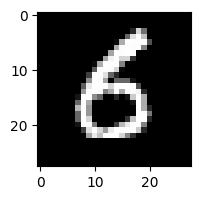

In [27]:

# Examples
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from keras.models import load_model
in_coding='clast'
out_coding='cat'

plt.figure(figsize = (2,2))
plt.grid(False)


if datagen==False:
    max_val=x_test.max()
    selectia=int(np.shape(x_test)[0]*np.random.rand(1)[0])  #
    img1=x_test[selectia,:,:,:]/max_val
    if np.shape(x_train)[3]==1:
      plt.imshow(img1[:,:,0],cmap='gray')
    elif np.shape(x_train)[3]==3:
      plt.imshow(img1)
    if out_coding=='cat':
        label=np.dot(y_test[selectia,:],1+np.array(range(num_classes)).T)
    elif out_coding=='non':
        label=y_test[selectia]
    print('Labeled class :', label-1)
    z=model.predict(x_test[selectia:selectia+1,:,:,:])
    print('Recognized class  : ',np.argmax(z))
else:
    for x_test,y_test in validation_generator: # test_generator: #
        break;

    selectia=int(sbatch_size*np.random.rand(1)[0])  #
    if in_coding=='cfirst':    # Cazul utilizari mediului Pytorch
        max_val=np.max(x_test)
        img1=x_test[selectia,:,:,:]/max_val
        img2=img1.permute(1, 2, 0).numpy()
        if np.shape(x_test)[1]==1:
          plt.imshow(img2[:,:,0],cmap='gray')
        elif np.shape(x_test)[1]==3:
          plt.imshow(img2)
    elif in_coding=='clast':
        max_val=np.max(x_test)
        img1=x_test[selectia,:,:,:]/max_val
        if np.shape(x_test)[3]==1:
          plt.imshow(img1[:,:,0],cmap='gray')
        elif np.shape(x_test)[3]==3:
          plt.imshow(img1)


    if out_coding=='cat':
            #labels=(np.dot(j,np.array(range(num_classes)).T)).astype('int16')
            label=np.dot(y_test[selectia,:],1+np.array(range(num_classes)).T)
    elif out_coding=='non':
            labels=y_test[selectia]
    print('Labeled class :', label-1)
    z=model.predict(x_test[selectia:selectia+1,:,:,:])
    print('Recognized class  : ',np.argmax(z))
